In [1]:
# [MXDL-11-03] 7.conv2D(cifar10).py
from tensorflow.keras.layers import Input, Dense, Conv2D, Flatten
from tensorflow.keras.layers import Dropout, BatchNormalization
from tensorflow.keras.layers import Activation, AveragePooling2D
from tensorflow.keras.layers import RandomFlip, RandomRotation
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import numpy as np
import matplotlib.pyplot as plt
import pickle
import pandas

# Load CIFAR10 dataset
from tensorflow.keras.datasets import cifar10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
x_train = x_train / 255.0
x_test = x_test / 255.0
with open('data/cifar10.pkl', 'wb') as f:
    pickle.dump([x_train, y_train, x_test, y_test], f)

with open('data/cifar10.pkl', 'rb') as f:
    x_train, y_train, x_test, y_test = pickle.load(f)

categories = ['airplane', 'automobile', 'bird', 'cat', 'deer',
              'dog', 'frog', 'horse', 'ship', 'truck']

# Build a 2D-CNN model
def Conv2D_Pool(x, filters, k_size, p_size):
    x = Conv2D(filters, k_size)(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = AveragePooling2D(p_size)(x)
    return x

x_input = Input(batch_shape=(None, *x_train.shape[1:]))
x = RandomFlip(mode='horizontal')(x_input)    # image augmentation
x = RandomRotation(0.1)(x)
h = Conv2D_Pool(x, 16, k_size=(3,3), p_size=(2,2))
h = Conv2D_Pool(h, 32, k_size=(3,3), p_size=(2,2))
h = Conv2D_Pool(h, 64, k_size=(3,3), p_size=(2,2))
h = Flatten()(h)
h = Dense(128, activation='relu')(h)
h = Dropout(0.5)(h)
y_output = Dense(10, activation='softmax')(h)

model = Model(x_input, y_output)
model.compile(loss='sparse_categorical_crossentropy',
              optimizer=Adam(learning_rate=0.001))
model.summary()

# Training
hist = model.fit(x_train, y_train,
                 epochs = 300,
                 batch_size = 1000,
                 validation_data = (x_test, y_test),
                 shuffle = True)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3051s 18us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 30, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 30, 30, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 15, 15, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 13, 13, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 6, 6, 32)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 4, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 2, 2, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,218 (227.41 KB)

 Trainable params: 57,994 (226.54 KB)

 Non-trainable params: 224 (896.00 B)

Epoch 1/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 111ms/step - loss: 1.9783 - val_loss: 2.2950
Epoch 2/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 1.6405 - val_loss: 2.5101
Epoch 3/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - loss: 1.5029 - val_loss: 2.8668
Epoch 4/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 103ms/step - loss: 1.4209 - val_loss: 2.8648
Epoch 5/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - loss: 1.3663 - val_loss: 2.8390
Epoch 6/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 133ms/step - loss: 1.3190 - val_loss: 2.7100
Epoch 7/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 115ms/step - loss: 1.2734 - val_loss: 2.3668
Epoch 8/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 142ms/step - loss: 1.2368 - val_loss: 2.2584
Epoch 9/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 157ms/step - loss: 1.2124 - val_loss: 2.4027
Epoch 10/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - loss: 1.1845 - val_loss: 1.7268
Epoch 11/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 119ms/step - loss: 1.1659 - val_loss: 1.7587
Epoch 12/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 6

In [2]:
# Build a 2D-CNN model
def Conv2D_Pool(x, filters, k_size, p_size):
    x = Conv2D(filters, k_size)(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = AveragePooling2D(p_size)(x)
    return x

x_input = Input(batch_shape=(None, *x_train.shape[1:]))
x = RandomFlip(mode='horizontal')(x_input)
x = RandomRotation(0.1)(x)
h = Conv2D_Pool(x, 16, k_size=(3,3), p_size=(2,2))
h = Conv2D_Pool(h, 32, k_size=(3,3), p_size=(2,2))
h = Conv2D_Pool(h, 64, k_size=(3,3), p_size=(2,2))
h = Flatten()(h)
h = Dense(128, activation='relu')(h)
h = Dropout(0.5)(h)
y_output = Dense(10, activation='softmax')(h)

model = Model(x_input, y_output)
model.compile(loss='sparse_categorical_crossentropy',
              optimizer=Adam(learning_rate=0.001))
model.summary()

# Training
hist = model.fit(x_train, y_train,
                 epochs = 300,
                 batch_size = 1000,
                 validation_data = (x_test, y_test),
                 shuffle = True)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 30, 30, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 30, 30, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_3             │ (None, 15, 15, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 13, 13, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_4             │ (None, 6, 6, 32)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 4, 4, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_5             │ (None, 2, 2, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,218 (227.41 KB)

 Trainable params: 57,994 (226.54 KB)

 Non-trainable params: 224 (896.00 B)

Epoch 1/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 180ms/step - loss: 1.9558 - val_loss: 2.2558
Epoch 2/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 174ms/step - loss: 1.6273 - val_loss: 2.4683
Epoch 3/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 175ms/step - loss: 1.5039 - val_loss: 2.6850
Epoch 4/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 165ms/step - loss: 1.4233 - val_loss: 2.7309
Epoch 5/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 192ms/step - loss: 1.3601 - val_loss: 2.5794
Epoch 6/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 171ms/step - loss: 1.3093 - val_loss: 2.4996
Epoch 7/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 167ms/step - loss: 1.2650 - val_loss: 2.2620
Epoch 8/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 162ms/step - loss: 1.2381 - val_loss: 2.2787
Epoch 9/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 169ms/step - loss: 1.2059 - val_loss: 1.6677
Epoch 10/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 167ms/step - loss: 1.1773 - val_loss: 1.4195
Epoch 11/300
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 160ms/step - loss: 1.1582 - val_loss: 1.3461
Epoch 12/300
50/50 ━━━━━━━━━━━━━━━━━━━━

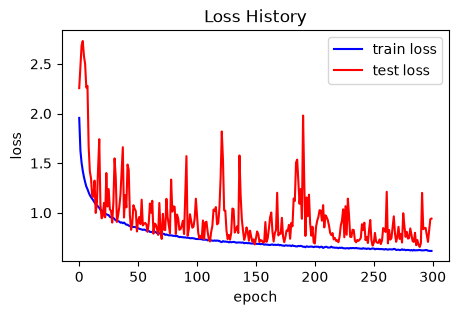

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Accuracy for the test data = 0.6998


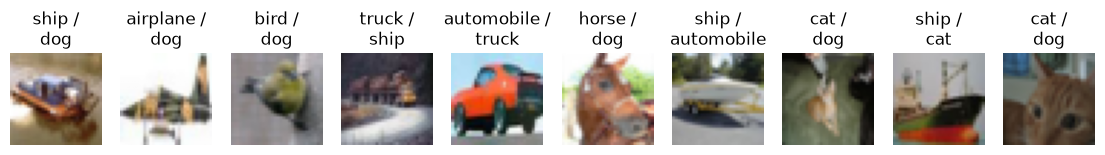

In [3]:
# Loss history
plt.figure(figsize=(5, 3))
plt.plot(hist.history['loss'], color='blue', label='train loss')
plt.plot(hist.history['val_loss'], color='red', label='test loss')
plt.legend()
plt.title("Loss History")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.show()

# Accuracy for test data
y_prob = model.predict(x_test)
y_pred = np.argmax(y_prob, axis=1).reshape(-1,1)
acc = (y_test == y_pred).mean()
print('Accuracy for the test data = {:.4f}'.format(acc))

# Check out some misclassified images
n_sample = 10
miss_cls = np.where(y_test != y_pred)[0]
miss_sam = np.random.choice(miss_cls, n_sample)

fig, ax = plt.subplots(1, n_sample, figsize=(14,4))
for i, miss in enumerate(miss_sam):
    ax[i].imshow(x_test[miss])
    ax[i].axis('off')
    s_test = categories[y_test[miss][0]]
    s_pred = categories[y_pred[miss][0]]
    ax[i].set_title(s_test + ' /\n' + s_pred)
plt.show()